In [1]:
import xarray as xr
import numpy as np

import cartopy.crs as ccrs
import cartopy.mpl.ticker as cticker
import cartopy.feature as feature
from cartopy.util import add_cyclic_point
from cartopy.mpl.ticker import (LongitudeFormatter, LatitudeFormatter)

import matplotlib.cm as cm
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
import matplotlib.patches as patches

In [2]:
# --- read mask

# input mask - Miocene
ds_mask = xr.open_dataset('../Miocene_LANDFRAC.nc')
var = 'LANDFRAC'
mask = ds_mask[var][0,:,:]

# Add cyclic point to mask
mask_Mio, lons = add_cyclic_point(mask, coord=ds_mask['lon'])

# ==================================================================
# input mask - Preindustrial
ds_mask = xr.open_dataset('../Preindustrial_LANDFRAC.nc')
var = 'LANDFRAC'
mask = ds_mask[var][0,:,:]

# Add cyclic point to mask
mask_Pi, lons = add_cyclic_point(mask, coord=ds_mask['lon'])

In [3]:
lat = ds_mask['lat']
lon = ds_mask['lon']
weights = np.cos(np.deg2rad(lat))

## Surface Dust

In [5]:
ds_dust = xr.open_dataset('./FigS9_Surface_Dust.nc')

# --- read variable: dst_a3 ---

dst_SRF_Pi_mean = ds_dust['Pi_SurfaceDust']
dst_SRF_Mio280_new_mean = ds_dust['Mio280_H12_SurfaceDust']
dst_SRF_Mio280_mean = ds_dust['Mio280_SurfaceDust']
dst_SRF_Mio560_mean = ds_dust['Mio560_SurfaceDust']
dst_SRF_Mio840_mean = ds_dust['Mio840_SurfaceDust']

dst_SRF_Pi_mean = xr.DataArray(data=dst_SRF_Pi_mean,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio280_mean = xr.DataArray(data=dst_SRF_Mio280_mean,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio280_new_mean = xr.DataArray(data=dst_SRF_Mio280_new_mean,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio560_mean = xr.DataArray(data=dst_SRF_Mio560_mean,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio840_mean = xr.DataArray(data=dst_SRF_Mio840_mean,dims=['lat','lon'],coords=[lat, lon])

In [6]:
dst_SRF_Mio280_Diff = dst_SRF_Mio280_mean - dst_SRF_Pi_mean
dst_SRF_Mio280_new_Diff = dst_SRF_Mio280_new_mean - dst_SRF_Pi_mean
dst_SRF_Mio560_Diff = dst_SRF_Mio560_mean - dst_SRF_Pi_mean
dst_SRF_Mio840_Diff = dst_SRF_Mio840_mean - dst_SRF_Pi_mean

dst_SRF_Mio280_compare = dst_SRF_Mio280_mean - dst_SRF_Mio280_new_mean
dst_SRF_Mio560_compare = dst_SRF_Mio560_mean - dst_SRF_Mio280_new_mean
dst_SRF_Mio840_compare = dst_SRF_Mio840_mean - dst_SRF_Mio280_new_mean

dst_SRF_Mio560_compare_DiffCO2 = dst_SRF_Mio560_mean - dst_SRF_Mio280_mean
dst_SRF_Mio840_compare_DiffCO2 = dst_SRF_Mio840_mean - dst_SRF_Mio280_mean

In [7]:
dst_SRF_Mio280_new_Diff = xr.DataArray(data=dst_SRF_Mio280_new_Diff,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio280_Diff = xr.DataArray(data=dst_SRF_Mio280_Diff,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio560_Diff = xr.DataArray(data=dst_SRF_Mio560_Diff,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio840_Diff = xr.DataArray(data=dst_SRF_Mio840_Diff,dims=['lat','lon'],coords=[lat, lon])

dst_SRF_Mio280_compare = xr.DataArray(data=dst_SRF_Mio280_compare,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio560_compare = xr.DataArray(data=dst_SRF_Mio560_compare,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio840_compare = xr.DataArray(data=dst_SRF_Mio840_compare,dims=['lat','lon'],coords=[lat, lon])

dst_SRF_Mio560_compare_DiffCO2 = xr.DataArray(data=dst_SRF_Mio560_compare_DiffCO2,dims=['lat','lon'],coords=[lat, lon])
dst_SRF_Mio840_compare_DiffCO2 = xr.DataArray(data=dst_SRF_Mio840_compare_DiffCO2,dims=['lat','lon'],coords=[lat, lon])

In [8]:
dst_SRF_Pi_gm = dst_SRF_Pi_mean.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio280_gm = dst_SRF_Mio280_mean.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio280_new_gm = dst_SRF_Mio280_new_mean.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio560_gm = dst_SRF_Mio560_mean.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio840_gm = dst_SRF_Mio840_mean.weighted(weights).mean(dim=['lon','lat']) 

print('----- global mean -----')
print(dst_SRF_Pi_gm.values)
print(dst_SRF_Mio280_gm.values)
print(dst_SRF_Mio280_new_gm.values)
print(dst_SRF_Mio560_gm.values)
print(dst_SRF_Mio840_gm.values)

dst_SRF_Mio280_Diff_gm = dst_SRF_Mio280_Diff.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio280_new_Diff_gm = dst_SRF_Mio280_new_Diff.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio560_Diff_gm = dst_SRF_Mio560_Diff.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio840_Diff_gm = dst_SRF_Mio840_Diff.weighted(weights).mean(dim=['lon','lat']) 

print('----- global mean anomalies -----')
print(dst_SRF_Mio280_Diff_gm.values)
print(dst_SRF_Mio280_new_Diff_gm.values)
print(dst_SRF_Mio560_Diff_gm.values)
print(dst_SRF_Mio840_Diff_gm.values)


dst_SRF_Mio280_compare_gm = dst_SRF_Mio280_compare.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio560_compare_gm = dst_SRF_Mio560_compare.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio840_compare_gm = dst_SRF_Mio840_compare.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio560_compare_DiffCO2_gm = dst_SRF_Mio560_compare_DiffCO2.weighted(weights).mean(dim=['lon','lat']) 
dst_SRF_Mio840_compare_DiffCO2_gm = dst_SRF_Mio840_compare_DiffCO2.weighted(weights).mean(dim=['lon','lat']) 

print('----- global mean compare to 280_new -----')
print(dst_SRF_Mio280_compare_gm.values)
print(dst_SRF_Mio560_compare_gm.values)
print(dst_SRF_Mio840_compare_gm.values)
print(dst_SRF_Mio560_compare_DiffCO2_gm.values)
print(dst_SRF_Mio840_compare_DiffCO2_gm.values)

dst_ratio_Mio280_Diff = 100*(dst_SRF_Mio280_Diff_gm / dst_SRF_Pi_gm)
dst_ratio_Mio280_new_Diff = 100*(dst_SRF_Mio280_new_Diff_gm / dst_SRF_Pi_gm)
dst_ratio_Mio560_Diff = 100*(dst_SRF_Mio560_Diff_gm / dst_SRF_Pi_gm)
dst_ratio_Mio840_Diff = 100*(dst_SRF_Mio840_Diff_gm / dst_SRF_Pi_gm)

print('----- changes [%] -----')
print(dst_ratio_Mio280_Diff.values)
print(dst_ratio_Mio280_new_Diff.values)
print(dst_ratio_Mio560_Diff.values)
print(dst_ratio_Mio840_Diff.values)

----- global mean -----
1.9156048075679348e-08
1.0466485224628006e-08
3.946786819586094e-09
1.0314789405134935e-08
1.1229022331003803e-08
----- global mean anomalies -----
-8.689562894969534e-09
-1.520926129542183e-08
-8.841258665910253e-09
-7.927025823901541e-09
----- global mean compare to 280_new -----
6.519698372466823e-09
6.368002567548524e-09
7.282235488376812e-09
-1.5169581940191416e-10
7.625371064545961e-10
----- changes [%] -----
-45.36198103408324
-79.39665444216342
-46.15387595072481
-41.381321411307944


In [9]:
dst_SRF_Mio280_mean, lons = add_cyclic_point(dst_SRF_Mio280_mean, coord=lon)
dst_SRF_Mio280_new_mean, lons = add_cyclic_point(dst_SRF_Mio280_new_mean, coord=lon)
dst_SRF_Mio560_mean, lons = add_cyclic_point(dst_SRF_Mio560_mean, coord=lon)
dst_SRF_Mio840_mean, lons = add_cyclic_point(dst_SRF_Mio840_mean, coord=lon)

dst_SRF_Mio280_compare, lons = add_cyclic_point(dst_SRF_Mio280_compare, coord=lon)
dst_SRF_Mio560_compare, lons = add_cyclic_point(dst_SRF_Mio560_compare, coord=lon)
dst_SRF_Mio840_compare, lons = add_cyclic_point(dst_SRF_Mio840_compare, coord=lon)
dst_SRF_Mio560_compare_DiffCO2, lons = add_cyclic_point(dst_SRF_Mio560_compare_DiffCO2, coord=lon)
dst_SRF_Mio840_compare_DiffCO2, lons = add_cyclic_point(dst_SRF_Mio840_compare_DiffCO2, coord=lon)

dst_SRF_Mio280_Diff, lons = add_cyclic_point(dst_SRF_Mio280_Diff, coord=lon)
dst_SRF_Mio280_new_Diff, lons = add_cyclic_point(dst_SRF_Mio280_new_Diff, coord=lon)
dst_SRF_Mio560_Diff, lons = add_cyclic_point(dst_SRF_Mio560_Diff, coord=lon)
dst_SRF_Mio840_Diff, lons = add_cyclic_point(dst_SRF_Mio840_Diff, coord=lon)

In [10]:
dust_Mio_compare = [dst_SRF_Mio280_new_mean, dst_SRF_Mio280_new_Diff, dst_SRF_Mio280_new_Diff, dst_SRF_Mio280_new_Diff,
                    dst_SRF_Mio280_mean, dst_SRF_Mio280_Diff, dst_SRF_Mio280_compare, dst_SRF_Mio280_compare,
                    dst_SRF_Mio560_mean, dst_SRF_Mio560_Diff, dst_SRF_Mio560_compare, dst_SRF_Mio560_compare_DiffCO2,
                    dst_SRF_Mio840_mean, dst_SRF_Mio840_Diff, dst_SRF_Mio840_compare, dst_SRF_Mio840_compare_DiffCO2]

/glade/derecho/scratch/pjchen/tmp/ipykernel_54698/250768214.py:15: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed two minor releases later. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap(obj)`` instead.
  base_cmap_Or = cm.get_cmap('Oranges', 256)


''

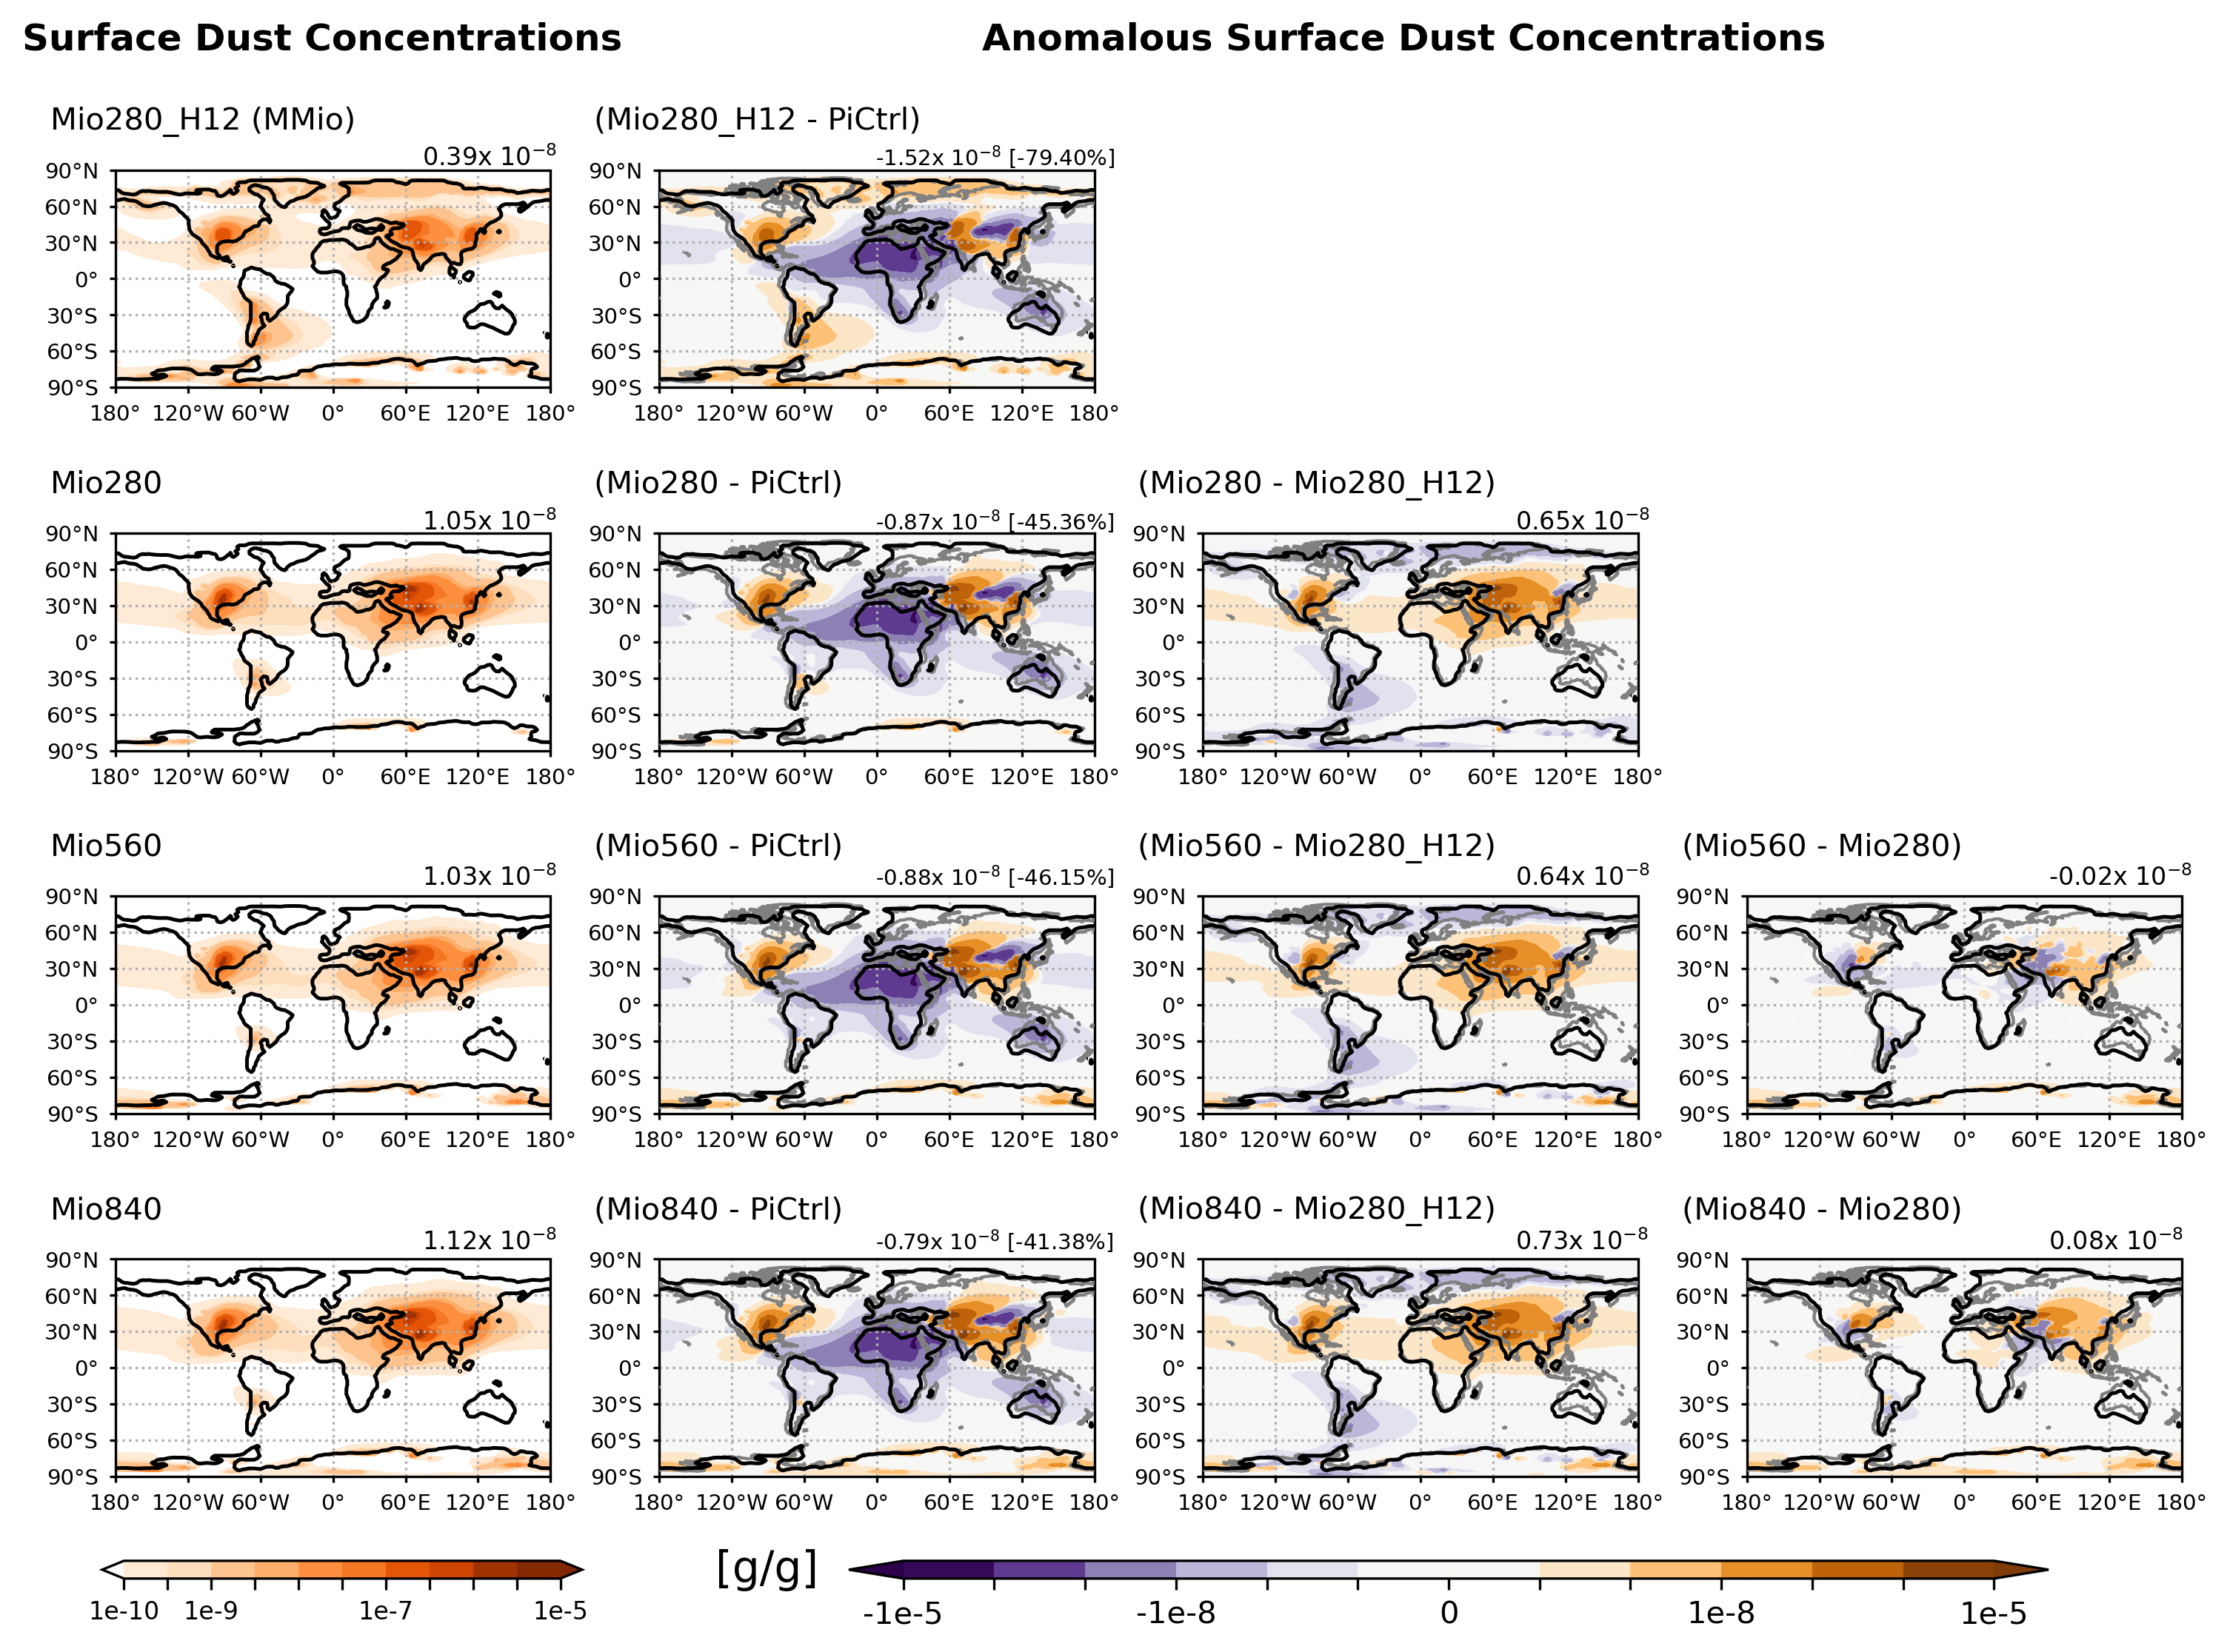

In [11]:
# Function of Plotting

data_title = 'Surface Dust Anomaly'
# plot_name = 'plot_surface_dust_anomaly_pattern'

levels1 = [1e-10, 5e-10, 1e-9, 5e-9, 1e-8, 5e-8, 1e-7, 5e-7, 1e-6, 5e-6, 1e-5]
levels_label1 = ['1e-10', '', '1e-9','', '', '', '1e-7', '', '', '', '1e-5']
levels2 = [-1e-5, -1e-6, -1e-7, -1e-8, -1e-9, -1e-10, 0, 1e-10, 1e-9, 1e-8, 1e-7, 1e-6, 1e-5]
levels_label2 = ['-1e-5', '', '', '-1e-8', '', '', '0', '', '', '1e-8', '', '', '1e-5']

norm1 = mcolors.SymLogNorm(linthresh=1e-10, linscale=1e-5, vmin=0, vmax=1e-5)
norm2 = mcolors.SymLogNorm(linthresh=1e-10, linscale=1e-4, vmin=-1e-5, vmax=1e-5)
locator = mticker.SymmetricalLogLocator(linthresh=0.0001, base=10)

base_cmap_Or = cm.get_cmap('Oranges', 256)
colors = base_cmap_Or(np.linspace(0, 1, 256))
colors[0] = [1, 1, 1, 1]  # minimum → white (RGBA)
cmap_Or = mcolors.ListedColormap(colors)

dust_patterns = ['Mio280_H12 (MMio)', '(Mio280_H12 - PiCtrl)', '(Mio280_H12 - PiCtrl)', '(Mio280_H12 - PiCtrl)',
                 'Mio280', '(Mio280 - PiCtrl)', '(Mio280 - Mio280_H12)', '(Mio280 - Mio280_H12)',
                 'Mio560', '(Mio560 - PiCtrl)', '(Mio560 - Mio280_H12)', '(Mio560 - Mio280)',
                 'Mio840', '(Mio840 - PiCtrl)', '(Mio840 - Mio280_H12)', '(Mio840 - Mio280)']

# Define the figure and each axis for the 4 rows and 4 columns
fig, axs = plt.subplots(nrows=4,ncols=4,
                        subplot_kw={'projection': ccrs.PlateCarree(central_longitude=0)},
                        figsize=(12,8), dpi=300)
    
# Set Width / Height padding between subplots, expressed as a fraction of the subplot width
fig.subplots_adjust(wspace=0.25, hspace=0.3) 
    
# flatten axs into a 1-D array
axs=axs.flatten()

# Loop over all of the anomalies and plot
for i,m in enumerate(dust_patterns):
        
    # Contour plot 
    if i%4 == 0:
        cs1=axs[i].contourf(lons, lat, dust_Mio_compare[i], levels = levels1,
                            norm = norm1, transform = ccrs.PlateCarree(), cmap=cmap_Or,extend='both')
        # Add coastines in Miocene Scenario
        axs[i].contour(lons, lat, mask_Mio, [0.5,1.5],
                       transform = ccrs.PlateCarree(), colors='k', linewidths=1.2, zorder=3)
    else:
        cs2=axs[i].contourf(lons, lat, dust_Mio_compare[i], levels = levels2,
                            norm = norm2, transform = ccrs.PlateCarree(), cmap='PuOr_r',extend='both')
        # Add coastines in Pre-industrial Scenario
        axs[i].coastlines(color='grey', zorder=3)
        # Add coastines in Miocene Scenario
        axs[i].contour(lons, lat, mask_Mio, [0.5,1.5],
                       transform = ccrs.PlateCarree(), colors='k', linewidths=1.2, zorder=4)
    
    
    # Longitude labels
    axs[i].set_xticks(np.arange(-180,181,60), crs=ccrs.PlateCarree())
    lon_formatter = cticker.LongitudeFormatter()  
    axs[i].xaxis.set_major_formatter(lon_formatter)  # set the format of xticks_label
    axs[i].tick_params(axis='x', size=2)             # set xtick parameters
    for xlabel in axs[i].get_xticklabels():          # set xticks_label
        xlabel.set_fontsize(7)        

    # Latitude labels
    axs[i].set_yticks(np.arange(-90,91,30), crs=ccrs.PlateCarree())
    lat_formatter = cticker.LatitudeFormatter()
    axs[i].yaxis.set_major_formatter(lat_formatter)  # set the format of yticks_label
    axs[i].tick_params(axis='y', size=2)             # set ytick parameters
    for ylabel in axs[i].get_yticklabels():          # set yticks_label
        ylabel.set_fontsize(7)        
        
    # Title each subplot with the name of the month
    axs[i].set_title(dust_patterns[i], fontsize=10, loc='left', x=-0.15, y=1.1)
        
    # Add gridlines
    axs[i].gridlines(zorder=2, linestyle=':')

# Add colorbar
cax1  = fig.add_axes([0.12, 0.07, 0.18, 0.01])    # set the [x0, y0, width, height] of the colorbar
CB1   = plt.colorbar(cs1, cax = cax1, orientation='horizontal')
CB1.set_ticks(levels1)
CB1.set_ticklabels(levels_label1, fontsize=8)

cax2  = fig.add_axes([0.4, 0.07, 0.45, 0.01])    # set the [x0, y0, width, height] of the colorbar
CB2   = plt.colorbar(cs2, cax = cax2, orientation='horizontal')
CB2.set_ticks(levels2)
CB2.set_ticklabels(levels_label2)

# --- left 1 column
GM_Mio280_new = str('{:03.2f}'.format(dst_SRF_Mio280_new_gm.values*1e8))+'x $10^{-8}$'
GM_Mio280 = str('{:03.2f}'.format(dst_SRF_Mio280_gm.values*1e8))+'x $10^{-8}$'
GM_Mio560 = str('{:03.2f}'.format(dst_SRF_Mio560_gm.values*1e8))+'x $10^{-8}$'
GM_Mio840 = str('{:03.2f}'.format(dst_SRF_Mio840_gm.values*1e8))+'x $10^{-8}$'

plt.figtext(0.24,0.865,GM_Mio280_new,fontsize=8)
plt.figtext(0.24,0.66,GM_Mio280,fontsize=8)
plt.figtext(0.24,0.46,GM_Mio560,fontsize=8)
plt.figtext(0.24,0.255,GM_Mio840,fontsize=8)

# --- right 3 columns
GM_Mio280_new_ano = str('{:03.2f}'.format(dst_SRF_Mio280_new_Diff_gm.values*1e8))+'x $10^{-8}$ ['+str('{:03.2f}'.format(dst_ratio_Mio280_new_Diff.values))+'%]'
GM_Mio280_ano = str('{:03.2f}'.format(dst_SRF_Mio280_Diff_gm.values*1e8))+'x $10^{-8}$ ['+str('{:03.2f}'.format(dst_ratio_Mio280_Diff.values))+'%]'
GM_Mio560_ano = str('{:03.2f}'.format(dst_SRF_Mio560_Diff_gm.values*1e8))+'x $10^{-8}$ ['+str('{:03.2f}'.format(dst_ratio_Mio560_Diff.values))+'%]'
GM_Mio840_ano = str('{:03.2f}'.format(dst_SRF_Mio840_Diff_gm.values*1e8))+'x $10^{-8}$ ['+str('{:03.2f}'.format(dst_ratio_Mio840_Diff.values))+'%]'

GM_Mio280_compare = str('{:03.2f}'.format(dst_SRF_Mio280_compare_gm.values*1e8))+'x $10^{-8}$'
GM_Mio560_compare = str('{:03.2f}'.format(dst_SRF_Mio560_compare_gm.values*1e8))+'x $10^{-8}$'
GM_Mio840_compare = str('{:03.2f}'.format(dst_SRF_Mio840_compare_gm.values*1e8))+'x $10^{-8}$'

GM_Mio560_compare_DiffCO2 = str('{:03.2f}'.format(dst_SRF_Mio560_compare_DiffCO2_gm.values*1e8))+'x $10^{-8}$'
GM_Mio840_compare_DiffCO2 = str('{:03.2f}'.format(dst_SRF_Mio840_compare_DiffCO2_gm.values*1e8))+'x $10^{-8}$'

fig.delaxes(axs[2])
fig.delaxes(axs[3])
fig.delaxes(axs[7])
plt.figtext(0.35,0.068,'[g/g]',fontsize=14)
plt.figtext(0.41,0.865,GM_Mio280_new_ano,fontsize=7)
plt.figtext(0.41,0.66,GM_Mio280_ano,fontsize=7)
plt.figtext(0.41,0.46,GM_Mio560_ano,fontsize=7)
plt.figtext(0.41,0.255,GM_Mio840_ano,fontsize=7)
plt.figtext(0.65,0.66,GM_Mio280_compare,fontsize=8)
plt.figtext(0.65,0.46,GM_Mio560_compare,fontsize=8)
plt.figtext(0.65,0.255,GM_Mio840_compare,fontsize=8)
plt.figtext(0.85,0.46,GM_Mio560_compare_DiffCO2,fontsize=8)
plt.figtext(0.85,0.255,GM_Mio840_compare_DiffCO2,fontsize=8)



# Add title
plt.figtext(0.09,0.93,'Surface Dust Concentrations',fontsize=12,fontweight='bold')
plt.figtext(0.45,0.93,'Anomalous Surface Dust Concentrations',fontsize=12,fontweight='bold')
# plt.suptitle(data_title, y=0.94, fontsize=15)
# fig.savefig(plot_name+'.png')
;